In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [15]:
# Load dataset
df = pd.read_csv("C:/Users/D E L L/Desktop/Real-Time-Anomaly-Detection-Alerting-System-IoT-Time-Series-/data/predictive_maintenance_dataset.csv")

In [16]:
#display first 5 rows of the dataset 
print(df.head())

             timestamp machine_id  vibration  acoustic  temperature  current  \
0  2024-07-01 08:00:00        M01      0.822     0.645        66.85    13.04   
1  2024-07-01 08:01:00        M01      1.398     0.834        76.20    15.08   
2  2024-07-01 08:02:00        M01      0.856     0.590        67.03    12.30   
3  2024-07-01 08:03:00        M01      0.793     0.544        65.04    11.69   
4  2024-07-01 08:04:00        M01      1.279     0.721        78.19    14.84   

   IMF_1  IMF_2  IMF_3  label  
0  0.196  0.033  0.000      0  
1  0.345  0.132  0.001      1  
2  0.187  0.017  0.002      0  
3  0.196 -0.060  0.003      0  
4  0.330 -0.115  0.004      1  


In [17]:
#dataset dimentions 
print("Shape:", df.shape)

Shape: (1800, 10)


In [18]:
#Column names 
print("Columns:", df.columns.tolist())

Columns: ['timestamp', 'machine_id', 'vibration', 'acoustic', 'temperature', 'current', 'IMF_1', 'IMF_2', 'IMF_3', 'label']


In [19]:
#display dataset information
df.info()  

<class 'pandas.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   timestamp    1800 non-null   str    
 1   machine_id   1800 non-null   str    
 2   vibration    1800 non-null   float64
 3   acoustic     1800 non-null   float64
 4   temperature  1800 non-null   float64
 5   current      1800 non-null   float64
 6   IMF_1        1800 non-null   float64
 7   IMF_2        1800 non-null   float64
 8   IMF_3        1800 non-null   float64
 9   label        1800 non-null   int64  
dtypes: float64(7), int64(1), str(2)
memory usage: 140.8 KB


In [20]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles and Folders:")
print(os.listdir())

Current Working Directory:
c:\Users\D E L L\Desktop\Real-Time-Anomaly-Detection-Alerting-System-IoT-Time-Series-\notebooks

Files and Folders:
['data_exploration.ipynb']


In [21]:
import os

print("Project Root:")
print(os.listdir("../"))

print("\nData Folder:")
print(os.listdir("../data"))

Project Root:
['.git', '.gitignore', '.venv', '.venv_old', 'config', 'dashboard', 'data', 'docs', 'LICENSE', 'main.py', 'models', 'notebooks', 'README.md', 'requirements.txt', 'scripts', 'src', 'tests']

Data Folder:
['predictive_maintenance_dataset.csv']


In [22]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
timestamp      0
machine_id     0
vibration      0
acoustic       0
temperature    0
current        0
IMF_1          0
IMF_2          0
IMF_3          0
label          0
dtype: int64


In [23]:
df.describe()

,vibration,acoustic,temperature,current,IMF_1,IMF_2,IMF_3,label
count,1800.000000,1800.000000,1800.000000,1800.00000,1800.000000,1800.000000,1800.000000,1800.000000
mean,0.843295,0.633898,66.355722,12.32860,0.168738,0.000072,0.000673,0.112222
std,0.136690,0.107989,4.448129,1.09451,0.056533,0.073104,0.036034,0.315727
min,0.645000,0.430000,58.360000,10.29000,0.073000,-0.180000,-0.050000,0.000000
25%,0.769000,0.572000,63.730000,11.70000,0.123000,-0.058000,-0.037000,0.000000
50%,0.805000,0.609000,65.355000,12.08000,0.166000,-0.001000,0.003500,0.000000
75%,0.851000,0.651250,66.990000,12.48000,0.207000,0.059000,0.037000,0.000000
max,1.405000,1.083000,85.160000,16.94000,0.393000,0.187000,0.050000,1.000000


In [24]:
print("Number of Duplicate Rows:")
print(df.duplicated().sum())

Number of Duplicate Rows:
0


In [27]:
print("Label Distribution:")
print(df["label"].value_counts())

print("\nLabel Percentage:")
print(df["label"].value_counts(normalize=True) * 100)

Label Distribution:
label
0    1598
1     202
Name: count, dtype: int64

Label Percentage:
label
0    88.777778
1    11.222222
Name: proportion, dtype: float64


In [26]:
print(df.columns.tolist())

['timestamp', 'machine_id', 'vibration', 'acoustic', 'temperature', 'current', 'IMF_1', 'IMF_2', 'IMF_3', 'label']


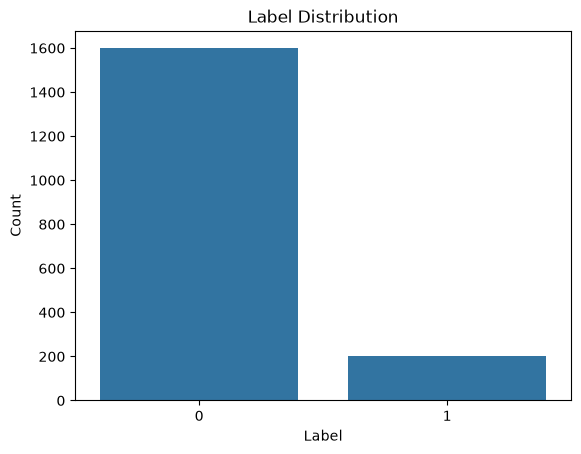

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")

plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

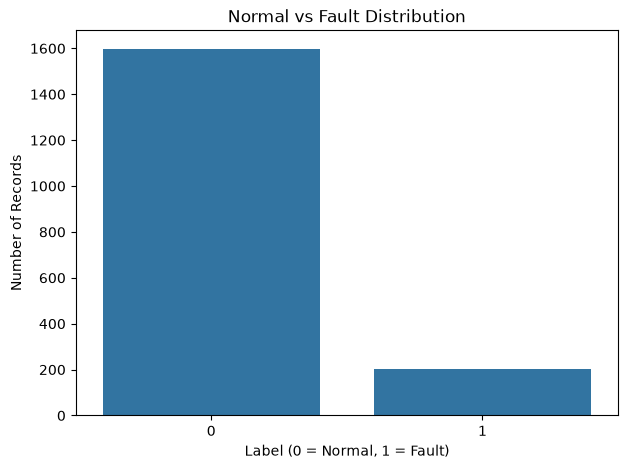

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Normal vs Fault Distribution")
plt.xlabel("Label (0 = Normal, 1 = Fault)")
plt.ylabel("Number of Records")

plt.show()

In [30]:
df.groupby("label")[["vibration","acoustic","temperature","current"]].mean()

,vibration,acoustic,temperature,current
label,,,,
0,0.798652,0.600558,64.959819,11.989587
1,1.196460,0.897644,77.398564,15.010495


In [32]:
sensor_columns = ["vibration","acoustic","temperature","current"]

sensor_comparison = df.groupby("label")[sensor_columns].mean()

sensor_comparison

,vibration,acoustic,temperature,current
label,,,,
0,0.798652,0.600558,64.959819,11.989587
1,1.196460,0.897644,77.398564,15.010495


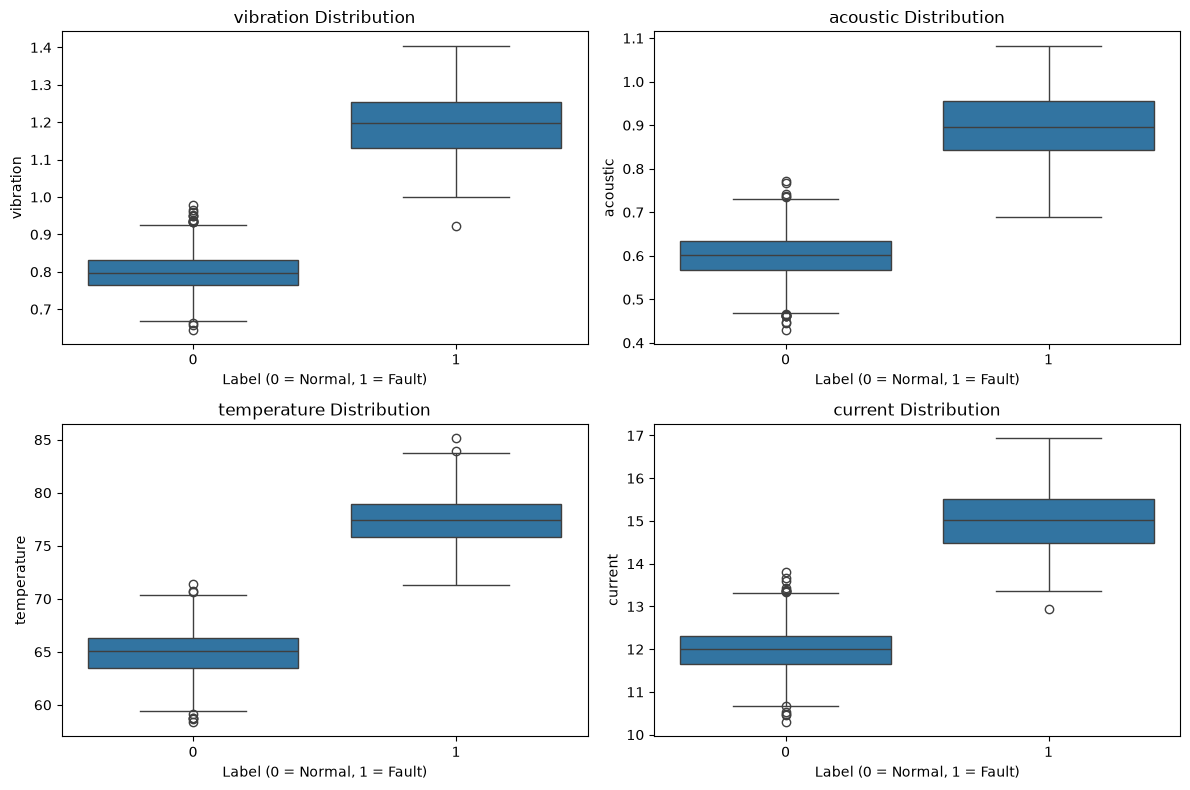

In [33]:
sensor_columns = ["vibration","acoustic","temperature","current"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(sensor_columns, axes.flatten()):
    sns.boxplot(data=df, x="label", y=column, ax=ax)
    ax.set_title(f"{column} Distribution")
    ax.set_xlabel("Label (0 = Normal, 1 = Fault)")

plt.tight_layout()
plt.show()

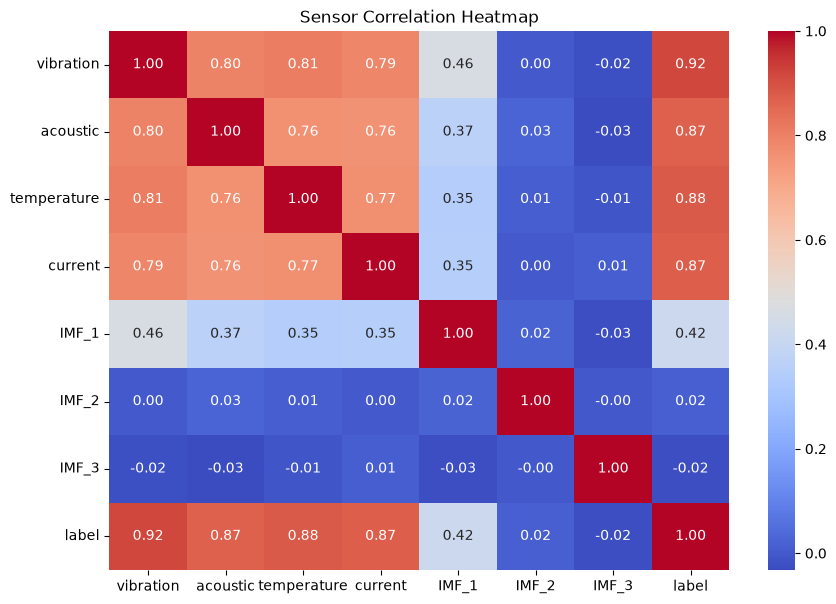

In [34]:
correlation = df[["vibration", "acoustic", "temperature", "current","IMF_1", "IMF_2", "IMF_3", "label"]].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Sensor Correlation Heatmap")
plt.show()

In [35]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print(numerical_columns)

Index(['vibration', 'acoustic', 'temperature', 'current', 'IMF_1', 'IMF_2',
       'IMF_3', 'label'],
      dtype='str')


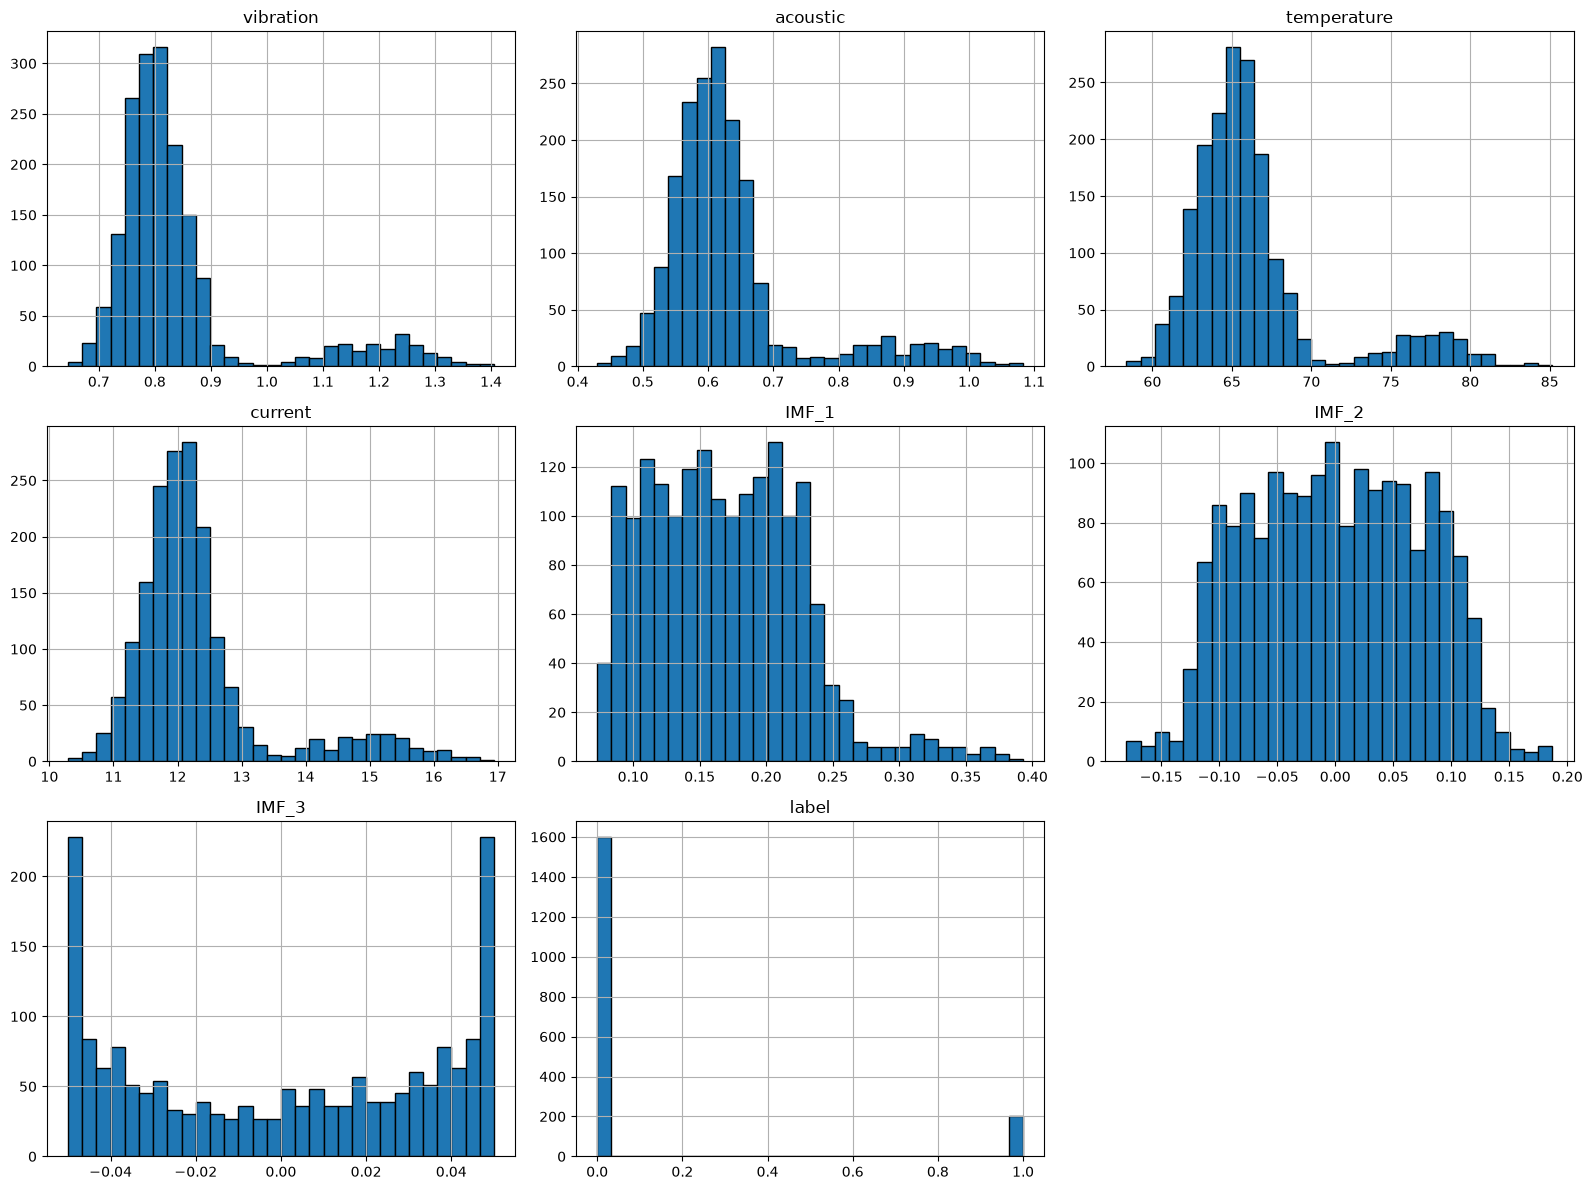

In [36]:
import matplotlib.pyplot as plt

df[numerical_columns].hist(figsize=(16, 12),bins=30,edgecolor='black')

plt.tight_layout()
plt.show()

In [37]:
categorical_columns = df.select_dtypes(include=['object']).columns

print(categorical_columns)

Index(['timestamp', 'machine_id'], dtype='str')


C:\Users\D E L L\AppData\Local\Temp\ipykernel_12112\4274052068.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


In [38]:
for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


timestamp
timestamp
2024-07-01 08:00:00    3
2024-07-01 08:01:00    3
2024-07-01 08:02:00    3
2024-07-01 08:03:00    3
2024-07-01 08:04:00    3
                      ..
2024-07-01 17:55:00    3
2024-07-01 17:56:00    3
2024-07-01 17:57:00    3
2024-07-01 17:58:00    3
2024-07-01 17:59:00    3
Name: count, Length: 600, dtype: int64

machine_id
machine_id
M01    600
M02    600
M03    600
Name: count, dtype: int64


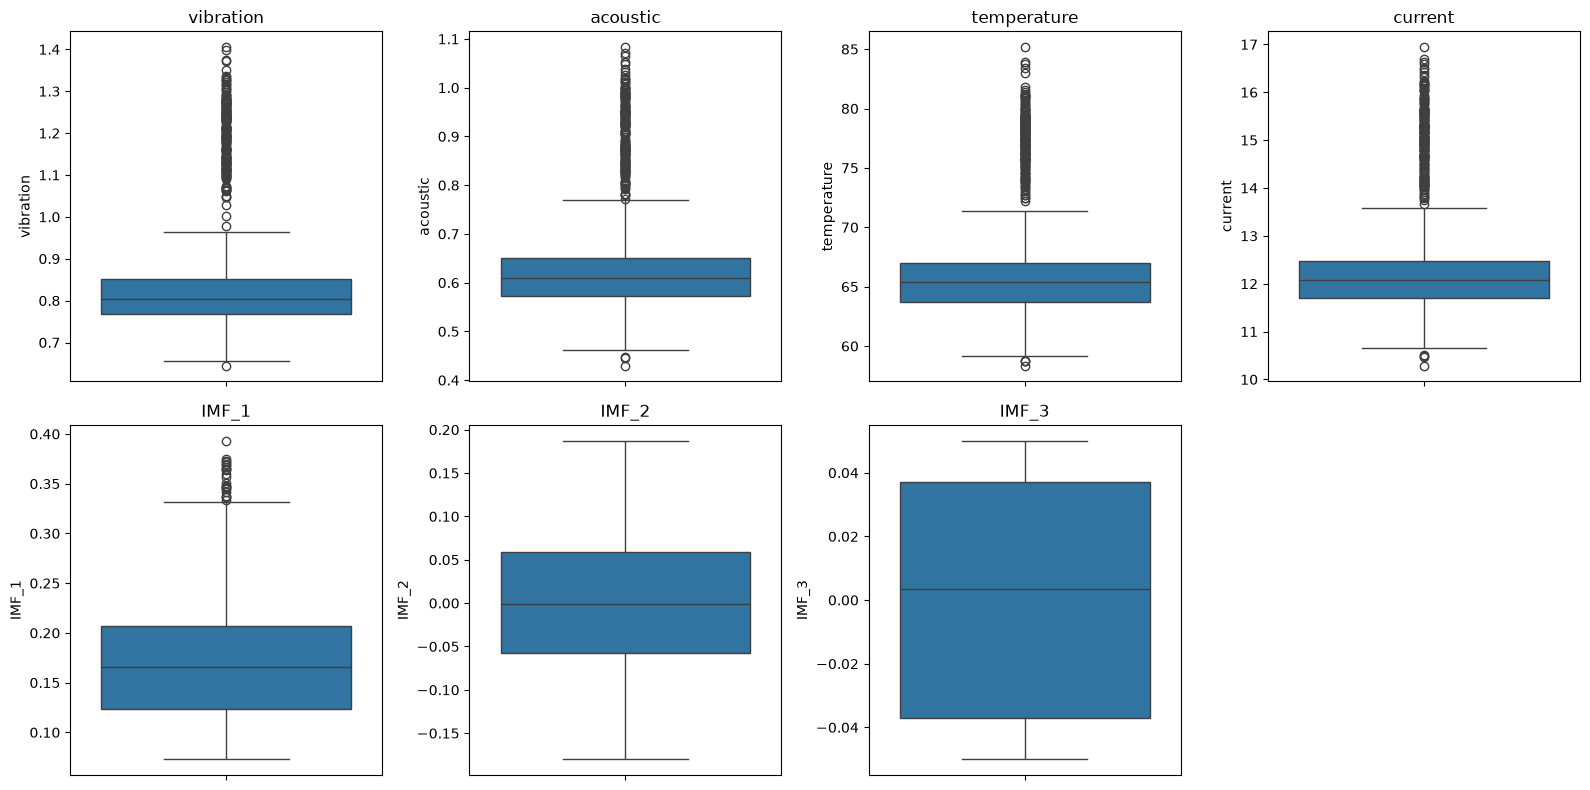

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Exclude target column
numerical_columns = numerical_columns.drop('label', errors='ignore')

plt.figure(figsize=(16, 8))

for i, col in enumerate(numerical_columns):
    plt.subplot(2, (len(numerical_columns) + 1) // 2, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [40]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Number of Outliers:", len(outliers))


vibration
Number of Outliers: 203

acoustic
Number of Outliers: 192

temperature
Number of Outliers: 205

current
Number of Outliers: 202

IMF_1
Number of Outliers: 23

IMF_2
Number of Outliers: 0

IMF_3
Number of Outliers: 0


In [41]:
correlation_matrix = df.corr(numeric_only=True)

print(correlation_matrix)

             vibration  acoustic  temperature   current     IMF_1     IMF_2  \
vibration     1.000000  0.796703     0.808277  0.790255  0.459981  0.002482   
acoustic      0.796703  1.000000     0.764509  0.760567  0.365972  0.028131   
temperature   0.808277  0.764509     1.000000  0.767776  0.346787  0.011637   
current       0.790255  0.760567     0.767776  1.000000  0.348885  0.003473   
IMF_1         0.459981  0.365972     0.346787  0.348885  1.000000  0.022382   
IMF_2         0.002482  0.028131     0.011637  0.003473  0.022382  1.000000   
IMF_3        -0.023653 -0.032130    -0.009848  0.009459 -0.027899 -0.003429   
label         0.918858  0.868588     0.882900  0.871425  0.418557  0.016049   

                IMF_3     label  
vibration   -0.023653  0.918858  
acoustic    -0.032130  0.868588  
temperature -0.009848  0.882900  
current      0.009459  0.871425  
IMF_1       -0.027899  0.418557  
IMF_2       -0.003429  0.016049  
IMF_3        1.000000 -0.024381  
label       -0.0

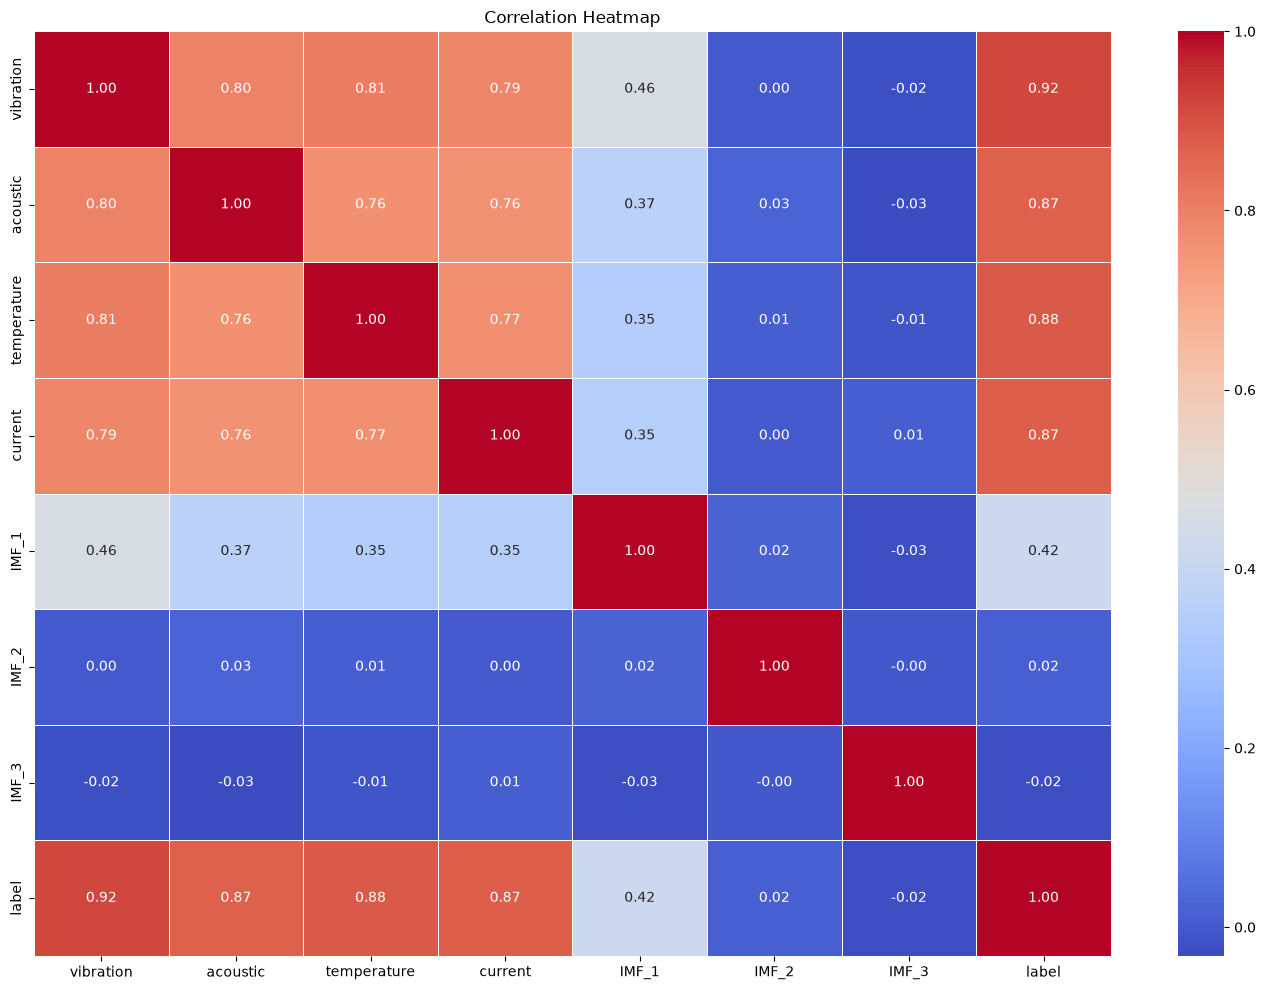

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [43]:
label_correlation = correlation_matrix['label'].drop('label')

label_correlation = label_correlation.sort_values(
    ascending=False
)

print("Correlation with Label:")
print(label_correlation)

Correlation with Label:
vibration      0.918858
temperature    0.882900
current        0.871425
acoustic       0.868588
IMF_1          0.418557
IMF_2          0.016049
IMF_3         -0.024381
Name: label, dtype: float64


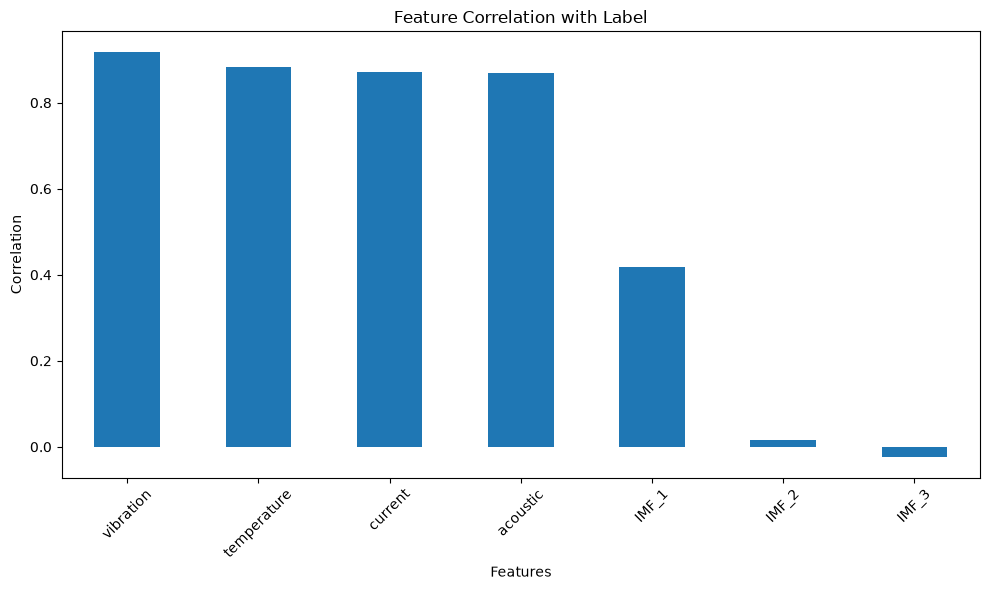

In [44]:
plt.figure(figsize=(10, 6))

label_correlation.plot(kind='bar')

plt.title("Feature Correlation with Label")
plt.xlabel("Features")
plt.ylabel("Correlation")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()